# NYC Ride-Hailing Demand Planning
### Congestion fee, Lyft credit, weather and a holiday-week forecast

**Setting.** It is 16 February 2025. New York started charging $1.50 on ride-hailing trips into the Manhattan congestion zone on 5 January. Lyft answered with a $1.50 future-ride credit until 31 January; Uber did not. The planning team needs to know what happened in January and how many trips to plan for the week of 17–23 February, which includes Presidents' Day.

**Data.** Every completed Uber and Lyft trip in NYC for January 2024, January 2025 and February 2025 (NYC TLC, 59.4 million trips after cleaning), hourly weather for Central Park (Open-Meteo, ERA5) and the US holiday calendar. Summer 2024 trips are added only for the rain study.

**Questions**

| # | Question | Section |
|---|---|---|
| 1 | What does normal demand look like, and which daily deviations deserve investigation? | 2 |
| 2 | Did the $1.50 fee reduce trips touching the zone? | 3 |
| 3 | Did Lyft's credit buy incremental trips, and at what cost? | 4 |
| 4 | How many trips should we plan for 17–23 February? | 5 |

## Executive summary

1. **Demand grew through volume, not price.** In matched three-week windows, completed trips rose 2.0% year on year and the average base fare 0.7%, so 73% of GMV growth came from more trips.
2. **The fee result is not a fee effect yet.** Zone-touching trips grew 9.5% slower than trips outside the zone (95% CI −10.9% to −8.0%). The same gap was already −13.8% on 2–4 January, before the fee existed, and the daily gap shows no break on 5 January. Over the same year, Uber's average zone fare rose 9.2% while Lyft's fell 5.8%. A clean estimate needs November–December data.
3. **Blanket credit is expensive.** Lyft's zone share rose 1.6 pp relative to its outside share while the credit ran, an uplift proxy of 6.2%. With an assumed $6 contribution per trip and full redemption, each incremental trip cost about $26. Break-even needs 33% uplift on a blanket credit, or 10% if credit is targeted at 30% of baseline trips.
4. **Weather moves demand less than published estimates.** Rain above 2 mm/h lifts trips by 7.7% and median wait by 0.9% (summer 2024, 35 hours). February has too few rain hours to estimate its own factor.
5. **Alerting needs a forecast band, not a fixed threshold.** A ±7% rule flags 118 of 360 segment-days. A band of 2.5 robust standard deviations around a two-week forecast flags 9, and 7 of those are explained by holidays or bad weather on a reference day.
6. **Plan 4.87 million trips for 17–23 February** using the mean of the two previous same weekdays (B2). In the backtest B2 scored 3.5% WAPE, better than adding an MLK holiday factor (3.6%) or using last week alone (4.4%).

**Recommendations:** use B2 for the holiday-week plan; replace blanket credit with a targeted test with a 10% randomized holdout; switch daily monitoring to forecast-based alerts; collect November–December data before quoting a fee effect.

## 0. Setup

The notebook runs end to end on Google Colab or Jupyter: it downloads about 2.9 GB of public data on the first run and reuses it afterwards. Large trip files are queried with DuckDB; pandas only handles daily and hourly aggregates.

In [1]:
import importlib.util
import subprocess
import sys

missing = [pkg for pkg in ("duckdb", "holidays", "pandas", "matplotlib", "requests") if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [2]:
from pathlib import Path
import json
import math

import duckdb
import holidays
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

ROOT = Path("urban-mobility-data")
RAW, EXT, OUT = ROOT / "raw", ROOT / "external", ROOT / "outputs"
for folder in (RAW, EXT, OUT):
    folder.mkdir(parents=True, exist_ok=True)

MAIN_MONTHS = ["2024-01", "2025-01", "2025-02"]
FEE_START = pd.Timestamp("2025-01-05")
CUTOFF = pd.Timestamp("2025-02-16")
WINDOWS = {"jan_2024": ("2024-01-08", "2024-01-28"),
           "jan_2025": ("2025-01-06", "2025-01-26"),
           "feb_2025": ("2025-02-03", "2025-02-23")}
SEGMENTS = [("Uber", True), ("Uber", False), ("Lyft", True), ("Lyft", False)]

TEAL, ORANGE, GREY, INK = "#157f78", "#d78335", "#9aa5b1", "#1f2933"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e7eb", "axes.axisbelow": True,
                     "axes.titlesize": 11, "axes.titlelocation": "left"})
pd.set_option("display.width", 160)


def save(df, name):
    df.to_csv(OUT / f"{name}.csv", index=False)
    return df


def segment_name(operator, touches_zone):
    return f"{operator} {'zone' if touches_zone else 'outside'}"

## 1. Data

### 1.1 Sources

In [3]:
TLC = "https://d37ci6vzurychx.cloudfront.net"
WEATHER_API = "https://archive-api.open-meteo.com/v1/archive"


def fetch(url, path, params=None):
    if path.exists():
        return path
    partial = path.with_suffix(path.suffix + ".part")
    with requests.get(url, params=params, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        with partial.open("wb") as f:
            for chunk in response.iter_content(1 << 22):
                f.write(chunk)
    partial.rename(path)
    return path


def fetch_trips(month):
    return fetch(f"{TLC}/trip-data/fhvhv_tripdata_{month}.parquet", RAW / f"fhvhv_tripdata_{month}.parquet")


def fetch_weather(name, start, end):
    params = {"latitude": 40.7812, "longitude": -73.9665, "start_date": start, "end_date": end,
              "hourly": "temperature_2m,rain,snowfall", "timezone": "America/New_York",
              "models": "era5", "temperature_unit": "celsius", "precipitation_unit": "mm"}
    path = fetch(WEATHER_API, EXT / f"weather_{name}.json", params)
    hourly = pd.DataFrame(json.loads(path.read_text())["hourly"])
    hourly = hourly.rename(columns={"time": "request_hour", "temperature_2m": "temperature_c",
                                    "rain": "rain_mm", "snowfall": "snowfall_cm"})
    hourly["request_hour"] = pd.to_datetime(hourly.request_hour)
    return hourly


def month_end(month):
    return str(pd.Period(month, freq="M").end_time.date())


trip_files = [fetch_trips(month) for month in MAIN_MONTHS]
zones = pd.read_csv(fetch(f"{TLC}/misc/taxi_zone_lookup.csv", EXT / "taxi_zone_lookup.csv"))
weather = pd.concat([fetch_weather(m, f"{m}-01", month_end(m)) for m in MAIN_MONTHS], ignore_index=True)
HOLIDAYS = {pd.Timestamp(day): name for day, name in holidays.US(years=[2024, 2025], observed=True).items()}

print(f"Trip files: {len(trip_files)} | zones: {len(zones)} | weather hours: {len(weather):,}")
print("Holidays in scope:", {d.date().isoformat(): n for d, n in HOLIDAYS.items() if d.month <= 2})

Trip files: 3 | zones: 265 | weather hours: 2,160
Holidays in scope: {'2024-01-01': "New Year's Day", '2024-01-15': 'Martin Luther King Jr. Day', '2024-02-19': "Washington's Birthday", '2025-01-01': "New Year's Day", '2025-01-20': 'Martin Luther King Jr. Day', '2025-02-17': "Washington's Birthday"}


### 1.2 Cleaning rules

A trip is kept when its request falls in one of the three study months, it is an Uber (`HV0003`) or Lyft (`HV0005`) trip, and both pickup and drop-off zones are known (zone 264 is "Unknown"). A trip with a bad fare, wait or distance stays in the trip count but is left out of that metric, so one broken field never removes demand.

In [4]:
con = duckdb.connect(str(ROOT / "trips.duckdb"))
con.execute("SET memory_limit = '4GB'")
con.register("known_zones", zones.loc[zones.LocationID.ne(264), ["LocationID"]])
con.sql(f"CREATE OR REPLACE VIEW raw_trips AS SELECT * FROM read_parquet({[str(p) for p in trip_files]}, union_by_name = true)")

IN_PERIOD = """(CAST(request_datetime AS DATE) BETWEEN DATE '2024-01-01' AND DATE '2024-01-31'
             OR CAST(request_datetime AS DATE) BETWEEN DATE '2025-01-01' AND DATE '2025-02-28')"""
KNOWN_ENDPOINTS = """(PULocationID IN (SELECT LocationID FROM known_zones)
                  AND DOLocationID IN (SELECT LocationID FROM known_zones))"""

funnel = con.sql(f'''
    WITH flags AS (
        SELECT {IN_PERIOD} AS in_period,
               hvfhs_license_num IN ('HV0003', 'HV0005') AS uber_or_lyft,
               {KNOWN_ENDPOINTS} AS known_endpoints
        FROM raw_trips
    )
    SELECT COUNT(*) AS raw_trips,
           SUM(CASE WHEN NOT in_period THEN 1 ELSE 0 END) AS request_outside_period,
           SUM(CASE WHEN in_period AND NOT uber_or_lyft THEN 1 ELSE 0 END) AS other_operator,
           SUM(CASE WHEN in_period AND uber_or_lyft AND NOT known_endpoints THEN 1 ELSE 0 END) AS unknown_zone,
           SUM(CASE WHEN in_period AND uber_or_lyft AND known_endpoints THEN 1 ELSE 0 END) AS retained
    FROM flags
''').df()

con.sql(f'''
    CREATE OR REPLACE TABLE trips AS
    SELECT
        CASE hvfhs_license_num WHEN 'HV0003' THEN 'Uber' ELSE 'Lyft' END AS operator,
        request_datetime,
        dropoff_datetime,
        CAST(request_datetime AS DATE) AS request_date,
        PULocationID AS pickup_zone,
        DOLocationID AS dropoff_zone,
        trip_miles,
        base_passenger_fare AS fare,
        driver_pay,
        cbd_congestion_fee AS fee,
        date_diff('second', request_datetime, pickup_datetime) / 60.0 AS wait_min,
        COALESCE(date_diff('second', request_datetime, pickup_datetime) BETWEEN 0 AND 3600, false) AS ok_wait,
        COALESCE(isfinite(base_passenger_fare) AND base_passenger_fare > 0, false) AS ok_fare,
        COALESCE(isfinite(driver_pay) AND driver_pay >= 0, false) AS ok_pay,
        COALESCE(isfinite(trip_miles) AND trip_miles > 0, false) AS ok_miles
    FROM raw_trips
    WHERE hvfhs_license_num IN ('HV0003', 'HV0005') AND {IN_PERIOD} AND {KNOWN_ENDPOINTS}
''')

quality = con.sql('''
    SELECT COUNT(*) AS trips,
           AVG(CASE WHEN ok_wait THEN 0 ELSE 1 END) AS wait_missing_or_outside_0_60_min,
           AVG(CASE WHEN ok_fare THEN 0 ELSE 1 END) AS fare_zero_or_negative,
           AVG(CASE WHEN ok_pay THEN 0 ELSE 1 END) AS driver_pay_negative,
           AVG(CASE WHEN ok_miles THEN 0 ELSE 1 END) AS distance_zero
    FROM trips
''').df()
display(funnel.astype(int).style.format("{:,}").hide(axis="index"))
display(quality.style.format({"trips": "{:,}"} | {c: "{:.3%}" for c in quality.columns[1:]}).hide(axis="index"))

raw_trips,request_outside_period,other_operator,unknown_zone,retained
"59,409,057","2,038",0,6,"59,407,013"


trips,wait_missing_or_outside_0_60_min,fare_zero_or_negative,driver_pay_negative,distance_zero
"59,407,013",0.982%,0.044%,0.001%,0.014%


### 1.3 Labelling the congestion zone

TLC does not publish which taxi zones sit inside the congestion relief zone, so the label is inferred from the data: a zone belongs to the fee zone when at least 95% of pickups there paid the fee between 5 and 31 January 2025. A trip **touches the zone** when its pickup or drop-off zone is on that list. 90% and 99% thresholds are kept for robustness checks.

The table below shows the zones with a fee rate between 50% and 99%. There is a clear break: no zone falls between 68% and 95%, so the label does not hinge on the exact threshold.

Two trip groups are defined once and fixed: **short trips** (< 2 miles) and **low-fare trips** (base fare at or below the 25th percentile of January 2024, $11.63).

In [5]:
zone_fee_rate = con.sql('''
    SELECT pickup_zone AS LocationID, COUNT(*) AS pickups,
           AVG(CASE WHEN fee > 0 THEN 1.0 ELSE 0.0 END) AS fee_rate
    FROM trips
    WHERE request_date BETWEEN DATE '2025-01-05' AND DATE '2025-01-31'
    GROUP BY pickup_zone
''').df().merge(zones, on="LocationID")

fee_zones = {t: zone_fee_rate.loc[zone_fee_rate.fee_rate >= t, ["LocationID"]] for t in (0.90, 0.95, 0.99)}
for t, z in fee_zones.items():
    con.register(f"zone_{round(t * 100)}", z)
LOW_FARE = con.sql('''
    SELECT quantile_cont(fare, 0.25) FROM trips
    WHERE request_date BETWEEN DATE '2024-01-01' AND DATE '2024-01-31' AND ok_fare
''').fetchone()[0]

con.sql(f'''
    CREATE OR REPLACE VIEW labeled AS
    SELECT *,
           pickup_zone IN (SELECT LocationID FROM zone_95) OR dropoff_zone IN (SELECT LocationID FROM zone_95) AS touches_zone,
           ok_miles AND trip_miles < 2 AS is_short,
           ok_fare AND fare <= {LOW_FARE!r} AS is_low_fare,
           ok_fare AND ok_pay AS ok_economics
    FROM trips
''')

crz = save(zone_fee_rate[zone_fee_rate.fee_rate >= 0.95].sort_values("LocationID"), "crz_zones")
print(f"Fee zone: {len(crz)} taxi zones ({len(fee_zones[0.90])} at 90%, {len(fee_zones[0.99])} at 99%). Low-fare threshold: ${LOW_FARE:.2f}")
borderline = zone_fee_rate[zone_fee_rate.fee_rate.between(0.5, 0.99)].sort_values("fee_rate", ascending=False)
borderline.assign(in_fee_zone=borderline.fee_rate >= 0.95)[["LocationID", "Borough", "Zone", "pickups", "fee_rate", "in_fee_zone"]] \
    .style.format({"pickups": "{:,}", "fee_rate": "{:.1%}"}).hide(axis="index")

Fee zone: 38 taxi zones (38 at 90%, 31 at 99%). Low-fare threshold: $11.63


LocationID,Borough,Zone,pickups,fee_rate,in_fee_zone
87,Manhattan,Financial District North,"103,096",98.9%,True
4,Manhattan,Alphabet City,"53,641",98.8%,True
246,Manhattan,West Chelsea/Hudson Yards,"193,249",98.6%,True
50,Manhattan,Clinton West,"93,752",98.5%,True
261,Manhattan,World Trade Center,"63,276",96.9%,True
88,Manhattan,Financial District South,"40,296",96.6%,True
13,Manhattan,Battery Park City,"83,591",95.8%,True
142,Manhattan,Lincoln Square East,"124,417",68.1%,False
199,Bronx,Rikers Island,3,66.7%,False
237,Manhattan,Upper East Side South,"155,327",63.3%,False


### 1.4 Planning tables

Everything after this point works on two small tables:

* `daily`: one row per day × operator × zone flag (90 days × 4 segments = 360 rows), the grain used for planning and campaign analysis.
* `hourly`: one row per hour for the whole city (2,160 rows), joined to weather.

Fares and driver pay are summed on the same valid sample, so average fare and driver pay per trip share a denominator.

In [6]:
METRICS = '''
    COUNT(*) AS trips,
    SUM(CASE WHEN is_short THEN 1 ELSE 0 END) AS short_trips,
    SUM(CASE WHEN is_low_fare THEN 1 ELSE 0 END) AS low_fare_trips,
    SUM(CASE WHEN ok_economics THEN 1 ELSE 0 END) AS economics_trips,
    SUM(CASE WHEN ok_economics THEN fare END) AS fare_sum,
    SUM(CASE WHEN ok_economics THEN driver_pay END) AS driver_pay_sum,
    MEDIAN(CASE WHEN ok_wait THEN wait_min END) AS median_wait
'''

daily = con.sql(f"SELECT request_date, operator, touches_zone, {METRICS} FROM labeled GROUP BY ALL ORDER BY ALL").df()
hourly = con.sql(f"SELECT date_trunc('hour', request_datetime) AS request_hour, {METRICS} FROM labeled GROUP BY ALL ORDER BY ALL").df()

daily["request_date"] = pd.to_datetime(daily.request_date).astype("datetime64[ns]")
hourly["request_hour"] = hourly.request_hour.astype("datetime64[ns]")
hourly = hourly.merge(weather, on="request_hour", how="left", validate="one_to_one")
hourly["request_date"] = hourly.request_hour.dt.normalize()
for table in (daily, hourly):
    table["is_holiday"] = table.request_date.isin(HOLIDAYS)
    table["day_of_week"] = table.request_date.dt.dayofweek
hourly["hour"] = hourly.request_hour.dt.hour

retained = int(funnel.retained.iloc[0])
checks = {
    "daily has 360 rows, one per day and segment": len(daily) == 360 and not daily.duplicated(["request_date", "operator", "touches_zone"]).any(),
    "hourly has 2,160 rows with weather": len(hourly) == 2160 and hourly.rain_mm.notna().all(),
    "daily trips = hourly trips = retained trips": daily.trips.sum() == hourly.trips.sum() == retained,
    "daily and hourly agree on every date": daily.groupby("request_date").trips.sum().equals(hourly.groupby("request_date").trips.sum()),
    "fare sums reconcile within 1 cent": abs(daily.fare_sum.sum() - hourly.fare_sum.sum()) < 0.01,
}
assert all(checks.values()), checks
save(daily, "daily_segment")
save(hourly, "hourly_city")
print(f"{retained:,} trips -> {len(daily)} daily rows and {len(hourly):,} hourly rows. All checks passed.")

59,407,013 trips -> 360 daily rows and 2,160 hourly rows. All checks passed.


## 2. Demand monitoring

### 2.1 Daily demand by segment

Uber trips outside the zone are the largest segment. Weekly seasonality dominates every series, and holidays (MLK on 15 Jan 2024 and 20 Jan 2025, Presidents' Day on 17 Feb 2025) show up as dips.

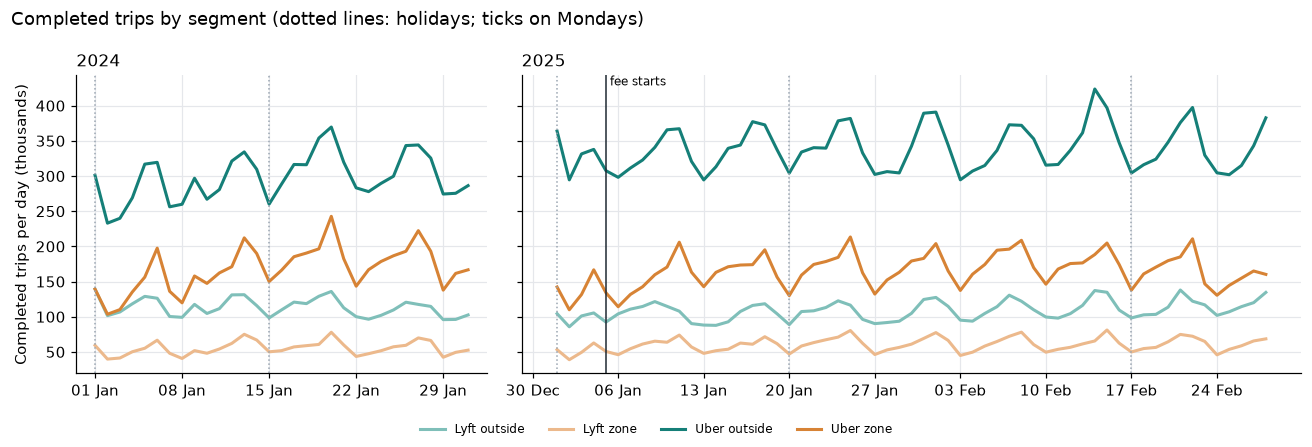

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, gridspec_kw={"width_ratios": [1, 1.9]})
colors = {("Uber", False): TEAL, ("Uber", True): ORANGE, ("Lyft", False): "#7fbfb9", ("Lyft", True): "#ecb98c"}
for ax, (start, end) in zip(axes, [("2024-01-01", "2024-01-31"), ("2025-01-01", "2025-02-28")]):
    part = daily[daily.request_date.between(start, end)]
    for (operator, zone), series in part.groupby(["operator", "touches_zone"]):
        ax.plot(series.request_date, series.trips / 1e3, color=colors[(operator, zone)], lw=2, label=segment_name(operator, zone))
    for day in [d for d in HOLIDAYS if start <= d.strftime("%Y-%m-%d") <= end]:
        ax.axvline(day, color=GREY, ls=":", lw=1)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.set_title(start[:4])
axes[1].axvline(FEE_START, color=INK, lw=1)
axes[1].text(FEE_START, axes[1].get_ylim()[1], " fee starts", va="top", fontsize=8)
axes[0].set_ylabel("Completed trips per day (thousands)")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, fontsize=8, loc="lower center", frameon=False)
fig.suptitle("Completed trips by segment (dotted lines: holidays; ticks on Mondays)", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

### 2.2 Growth = trips × average fare

GMV is approximated as trips × average base fare. Base fare excludes the congestion fee, taxes and tips, so this is a proxy rather than accounting GMV. Taking logs splits a change in GMV exactly into a **volume** part and a **price** part. The platform share proxy is 1 − driver pay ÷ base fare.

In [8]:
def window_economics(daily):
    rows = []
    for window, (start, end) in WINDOWS.items():
        data = daily[daily.request_date.between(start, end)]
        groups = [(op, zone, data[(data.operator == op) & (data.touches_zone == zone)]) for op, zone in SEGMENTS]
        for operator, zone, g in groups + [("All", "All", data)]:
            avg_fare = g.fare_sum.sum() / g.economics_trips.sum()
            rows.append({"window": window, "operator": operator, "touches_zone": zone, "trips": g.trips.sum(),
                         "avg_fare": avg_fare, "driver_pay_per_trip": g.driver_pay_sum.sum() / g.economics_trips.sum(),
                         "platform_share": 1 - g.driver_pay_sum.sum() / g.fare_sum.sum(),
                         "gmv_proxy": g.trips.sum() * avg_fare})
    return pd.DataFrame(rows)


def decompose(economics, before, after):
    a = economics[economics.window == before].set_index(["operator", "touches_zone"])
    b = economics[economics.window == after].set_index(["operator", "touches_zone"])
    out = pd.DataFrame({"trips_growth": b.trips / a.trips - 1, "avg_fare_growth": b.avg_fare / a.avg_fare - 1,
                        "gmv_growth": b.gmv_proxy / a.gmv_proxy - 1,
                        "platform_share_change_pp": 100 * (b.platform_share - a.platform_share)})
    out["volume_share_of_growth"] = np.log1p(out.trips_growth) / np.log1p(out.gmv_growth)
    return out.reset_index().assign(comparison=f"{before} -> {after}")


economics = save(window_economics(daily), "economics_windows")
growth = save(pd.concat([decompose(economics, "jan_2024", "jan_2025"),
                         decompose(economics, "jan_2025", "feb_2025")]), "gmv_decomposition")
total = growth[growth.operator == "All"].set_index("comparison").volume_share_of_growth
print("Share of GMV growth coming from trip volume: " + ", ".join(f"{k}: {v:.0%}" for k, v in total.items()))
growth.drop(columns="volume_share_of_growth").set_index(["comparison", "operator", "touches_zone"]).style.format(
    {"trips_growth": "{:+.1%}", "avg_fare_growth": "{:+.1%}", "gmv_growth": "{:+.1%}", "platform_share_change_pp": "{:+.1f}"})

Share of GMV growth coming from trip volume: jan_2024 -> jan_2025: 73%, jan_2025 -> feb_2025: 53%


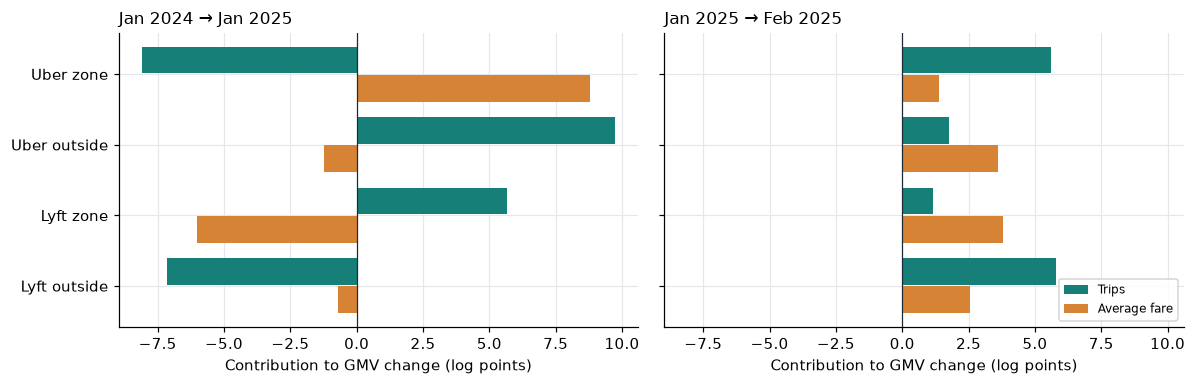

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, sharex=True)
for ax, (label, g) in zip(axes, growth[growth.operator != "All"].groupby("comparison", sort=False)):
    y = np.arange(len(g))
    ax.barh(y - 0.2, 100 * np.log1p(g.trips_growth), 0.38, color=TEAL, label="Trips")
    ax.barh(y + 0.2, 100 * np.log1p(g.avg_fare_growth), 0.38, color=ORANGE, label="Average fare")
    ax.set_yticks(y, [segment_name(o, z) for o, z in zip(g.operator, g.touches_zone)])
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_title(label.replace("_", " ").replace("jan", "Jan").replace("feb", "Feb").replace("->", "→"))
    ax.set_xlabel("Contribution to GMV change (log points)")
axes[0].invert_yaxis()
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Reading.** Year on year, total GMV grew 2.7%, three quarters of it from more trips. Inside the zone the two platforms moved in opposite directions: Uber's average fare rose 9.2% while its trips fell 7.8%; Lyft's fare fell 5.8% while its trips rose 5.8%. Uber also kept 3.8 pp more of each zone fare. Pricing changes between the two platforms are a competing explanation for anything later attributed to the fee or the credit.

### 2.3 Weather

Each hour is compared with dry, non-holiday hours of the same year, month, weekday and hour. Hours with drizzle below 0.5 mm are left out so the groups stay distinct, and snow takes priority over rain.

January and February contain only a handful of heavy-rain hours, so a summer window was added. It was chosen from the 2024 weather record alone, before looking at any trip data: the three consecutive months with at least 20 heavy-rain hours and the most separate rain events.

In [10]:
def classify_weather(frame):
    frame = frame.sort_values("request_hour").copy()
    frame["weather"] = np.select(
        [frame.snowfall_cm > 0, frame.rain_mm > 2, frame.rain_mm >= 0.5, frame.rain_mm > 0],
        ["snow", "rain > 2 mm/h", "rain 0.5-2 mm/h", "drizzle"], "dry")
    wet = (frame.rain_mm > 0) | (frame.snowfall_cm > 0)
    new_event = wet & (~wet.shift(fill_value=False) | frame.request_hour.diff().ne(pd.Timedelta(hours=1)))
    frame["event_id"] = new_event.cumsum().where(wet)
    frame["request_date"] = frame.request_hour.dt.normalize()
    frame["is_holiday"] = frame.request_date.isin(HOLIDAYS)
    for part in ("year", "month", "dayofweek", "hour"):
        frame[part] = getattr(frame.request_hour.dt, part)
    return frame


year_2024 = classify_weather(fetch_weather("2024_full_year", "2024-01-01", "2024-12-31"))
heavy = year_2024[(year_2024.weather == "rain > 2 mm/h") & ~year_2024.is_holiday]
windows = pd.DataFrame([{"months": f"{m:02d}-{m + 2:02d}",
                         "heavy_rain_hours": heavy.month.between(m, m + 2).sum(),
                         "rain_events": heavy[heavy.month.between(m, m + 2)].event_id.nunique()} for m in range(1, 11)])
chosen = windows[windows.heavy_rain_hours >= 20].sort_values(["rain_events", "heavy_rain_hours"], ascending=False).iloc[0]
RAIN_MONTHS = [f"2024-{m:02d}" for m in range(int(chosen.months[:2]), int(chosen.months[:2]) + 3)]
print(f"Rain study window: {RAIN_MONTHS[0]} to {RAIN_MONTHS[-1]} "
      f"({chosen.heavy_rain_hours} heavy-rain hours in {chosen.rain_events} events)")
windows.T

Rain study window: 2024-06 to 2024-08 (35 heavy-rain hours in 14 events)


,0,1,2,3,4,5,6,7,8,9
months,01-03,02-04,03-05,04-06,05-07,06-08,07-09,08-10,09-11,10-12
heavy_rain_hours,48,47,46,31,22,35,19,17,11,21
rain_events,9,9,8,10,9,14,8,7,3,5


In [11]:
summer_files = [str(fetch_trips(m)) for m in RAIN_MONTHS]
summer = con.sql(f'''
    SELECT date_trunc('hour', request_datetime) AS request_hour,
           COUNT(*) AS trips,
           MEDIAN(CASE WHEN wait BETWEEN 0 AND 60 THEN wait END) AS median_wait
    FROM (
        SELECT request_datetime, date_diff('second', request_datetime, pickup_datetime) / 60.0 AS wait
        FROM read_parquet({summer_files}, union_by_name = true)
        WHERE hvfhs_license_num IN ('HV0003', 'HV0005') AND {KNOWN_ENDPOINTS}
          AND request_datetime >= TIMESTAMP '{RAIN_MONTHS[0]}-01'
          AND request_datetime < TIMESTAMP '{RAIN_MONTHS[0]}-01' + INTERVAL 3 MONTH
    )
    GROUP BY ALL
''').df().astype({"request_hour": "datetime64[ns]"})
summer_weather = pd.concat([fetch_weather(m, f"{m}-01", month_end(m)) for m in RAIN_MONTHS])
summer = classify_weather(summer.merge(summer_weather, on="request_hour", validate="one_to_one"))


def weather_factors(hours, study):
    keys = ["year", "month", "dayofweek", "hour"]
    dry = hours[(hours.weather == "dry") & ~hours.is_holiday]
    base = dry.groupby(keys).agg(dry_trips=("trips", "median"), dry_wait=("median_wait", "median")).reset_index()
    hours = hours.merge(base, on=keys, how="left")
    usable = ~hours.is_holiday & (hours.weather != "drizzle")
    hours["trip_ratio"] = (hours.trips / hours.dry_trips).where(usable)
    hours["wait_ratio"] = (hours.median_wait / hours.dry_wait).where(usable)
    return (hours[hours.trip_ratio.notna()].groupby("weather")
            .agg(hours=("trip_ratio", "size"), rain_events=("event_id", "nunique"),
                 trips_factor=("trip_ratio", "median"), wait_factor=("wait_ratio", "median"))
            .reset_index().assign(study=study))


winter = classify_weather(hourly)
rain_factors = save(pd.concat([weather_factors(summer, "summer 2024"),
                               weather_factors(winter[winter.year == 2024], "winter 2024"),
                               weather_factors(winter[winter.year == 2025], "winter 2025")]), "rain_factors")
rain_factors = rain_factors[rain_factors.weather != "dry"]
rain_factors["small_sample"] = rain_factors.hours < 20
rain_factors.set_index(["study", "weather"]).style.format({"trips_factor": "{:.3f}", "wait_factor": "{:.3f}"})

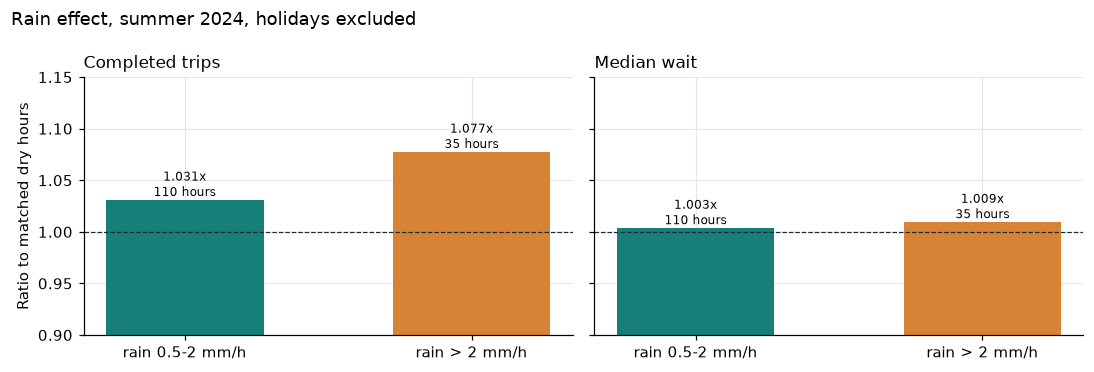

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
view = rain_factors[rain_factors.study == "summer 2024"].set_index("weather").loc[["rain 0.5-2 mm/h", "rain > 2 mm/h"]]
for ax, column, title in zip(axes, ["trips_factor", "wait_factor"], ["Completed trips", "Median wait"]):
    bars = ax.bar(view.index, view[column], color=[TEAL, ORANGE], width=0.55)
    ax.bar_label(bars, [f"{v:.3f}x\n{h} hours" for v, h in zip(view[column], view.hours)], fontsize=8)
    ax.axhline(1, color=INK, lw=0.8, ls="--")
    ax.set_ylim(0.9, 1.15)
    ax.set_title(title)
axes[0].set_ylabel("Ratio to matched dry hours")
fig.suptitle("Rain effect, summer 2024, holidays excluded", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Reading.** Heavy summer rain lifts completed trips by about 8% and median wait by about 1%. Published work on NYC found Uber trips up around 25% in rain hours (Brodeur & Nield, 2018); the gap may reflect today's larger supply or surge pricing absorbing the extra demand, but this data cannot separate the two. Winter groups with fewer than 20 hours are flagged and should not drive planning.

### 2.4 Alerting: from a fixed threshold to a forecast band

A common first rule compares each segment-day with the average of the same weekday one and two weeks earlier and alerts when trips move more than ±7% (or wait more than ±20%). The check below shows why that rule is too noisy, then replaces it with a band calibrated on how much that same forecast normally misses.

In [13]:
def fixed_threshold_alerts(daily):
    table = daily.set_index(["request_date", "operator", "touches_zone"])[["trips", "median_wait"]]
    def lagged(days):
        shifted = table.copy()
        shifted.index = shifted.index.set_levels(shifted.index.levels[0] + pd.Timedelta(days=days), level=0)
        return shifted.reindex(table.index)
    d7, d14, d364 = lagged(7), lagged(14), lagged(364)
    two_weeks = d7.notna().all(axis=1) & d14.notna().all(axis=1)
    expected = (d7 + d14) / 2
    expected.loc[~two_weeks] = d364.loc[~two_weeks]
    deviation = table / expected - 1
    alert = deviation.trips.abs().gt(0.07) | deviation.median_wait.abs().gt(0.20)
    return deviation.assign(alert=alert).reset_index()


fixed = fixed_threshold_alerts(daily)
print(f"Fixed ±7% rule: {fixed.alert.sum()} alerts on {fixed[fixed.alert].request_date.nunique()} of 90 days")

Fixed ±7% rule: 118 alerts on 58 of 90 days


In [14]:
def band_alerts(table, k=2.5, floor=0.03):
    # Expected = mean of the two most recent same-weekday days within five weeks,
    # skipping holidays and 1-7 January.
    counts = table.set_index(["request_date", "operator", "touches_zone"]).trips
    usable = lambda d: d not in HOLIDAYS and not (d.month == 1 and d.day <= 7)
    rows = []
    for (day, operator, zone), actual in counts.items():
        refs = [day - pd.Timedelta(days=lag) for lag in (7, 14, 21, 28, 35)]
        refs = [d for d in refs if (d, operator, zone) in counts.index and usable(d)][:2]
        expected = np.mean([counts[(d, operator, zone)] for d in refs]) if refs else np.nan
        event = "holiday" if day in HOLIDAYS else ""
        rows.append({"request_date": day, "operator": operator, "touches_zone": zone, "trips": actual,
                     "expected": expected, "references": len(refs),
                     "reference_dates": ", ".join(d.strftime("%d %b") for d in refs), "known_event": event})
    out = pd.DataFrame(rows)
    out["log_ratio"] = np.log(out.trips / out.expected)
    calibration = out[(out.known_event == "") & (out.references == 2)]
    stats = calibration.groupby(["operator", "touches_zone"]).log_ratio.agg(
        center="median", robust_sd=lambda x: 1.4826 * (x - x.median()).abs().median()).reset_index()
    out = out.merge(stats, on=["operator", "touches_zone"])
    scale = np.where(out.references == 1, math.sqrt(4 / 3), 1.0)
    out["z"] = (out.log_ratio - out.center) / (out.robust_sd * scale)
    out["alert"] = (out.log_ratio - out.center).abs() > np.maximum(k * out.robust_sd, math.log(1 + floor)) * scale
    return out, stats


band, band_stats = band_alerts(daily)
band_stats["fixed_rule_in_sd"] = math.log(1.07) / band_stats.robust_sd
display(band_stats.style.format({"center": "{:+.3f}", "robust_sd": "{:.3f}", "fixed_rule_in_sd": "{:.2f}"}).hide(axis="index"))

sensitivity = pd.DataFrame([{"k": k, "false_alarm_rate_if_normal": math.erfc(k / math.sqrt(2)),
                             "alerts": int(((band.z.abs() > k) & ((band.log_ratio - band.center).abs() > math.log(1.03))).sum())}
                            for k in (2.0, 2.5, 3.0)])
display(sensitivity.style.format({"k": "{:.1f}", "false_alarm_rate_if_normal": "{:.1%}"}).hide(axis="index"))

operator,touches_zone,center,robust_sd,fixed_rule_in_sd
Lyft,False,+0.030,0.062,1.09
Lyft,True,-0.005,0.064,1.06
Uber,False,-0.002,0.048,1.42
Uber,True,+0.018,0.065,1.05


k,false_alarm_rate_if_normal,alerts
2.0,4.6%,21
2.5,1.2%,9
3.0,0.3%,3


The normal day-to-day miss of a two-week forecast is 5–6% per segment. A ±7% threshold is only 1.0–1.4 standard deviations wide, so roughly a third of all days alert by chance. At 2.5 standard deviations the band raises 9 alerts. The table attaches the weather on the alert day and on its reference days, the first two things an analyst checks.

In [15]:
rainy = hourly.groupby("request_date").agg(rain_h=("rain_mm", lambda x: int((x >= 0.5).sum())),
                                           snow_h=("snowfall_cm", lambda x: int((x > 0).sum())))
describe = lambda d: f"{d:%d %b}: rain {rainy.loc[d, 'rain_h']}h, snow {rainy.loc[d, 'snow_h']}h"
alerts = band[band.alert].copy()
alerts["weather_on_day"] = alerts.request_date.map(describe)
alerts["weather_on_references"] = [
    "; ".join(describe(pd.Timestamp(f"{text} {day.year}")) for text in refs.split(", "))
    for day, refs in zip(alerts.request_date, alerts.reference_dates)]
save(band.drop(columns=["center", "robust_sd"]), "forecast_band_alerts")
alerts[["request_date", "operator", "touches_zone", "trips", "expected", "z", "known_event",
        "weather_on_day", "weather_on_references"]].style.format(
    {"request_date": "{:%d %b %Y}", "trips": "{:,.0f}", "expected": "{:,.0f}", "z": "{:+.1f}"})

,request_date,operator,touches_zone,trips,expected,z,known_event,weather_on_day,weather_on_references
57,15 Jan 2024,Lyft,True,"50,171","40,718",+2.9,holiday,"15 Jan: rain 0h, snow 2h","08 Jan: rain 0h, snow 0h"
59,15 Jan 2024,Uber,True,"150,028","119,767",+2.8,holiday,"15 Jan: rain 0h, snow 2h","08 Jan: rain 0h, snow 0h"
66,17 Jan 2024,Uber,False,"316,435","267,023",+3.1,,"17 Jan: rain 0h, snow 0h","10 Jan: rain 4h, snow 0h"
67,17 Jan 2024,Uber,True,"185,352","147,417",+2.8,,"17 Jan: rain 0h, snow 0h","10 Jan: rain 4h, snow 0h"
88,23 Jan 2024,Lyft,False,"96,470","113,670",-3.1,,"23 Jan: rain 0h, snow 0h","16 Jan: rain 1h, snow 18h; 09 Jan: rain 10h, snow 0h"
104,27 Jan 2024,Lyft,False,"117,541","133,649",-2.6,,"27 Jan: rain 0h, snow 0h","20 Jan: rain 0h, snow 0h; 13 Jan: rain 7h, snow 0h"
180,15 Jan 2025,Lyft,False,"92,806","114,609",-3.4,,"15 Jan: rain 0h, snow 0h","08 Jan: rain 0h, snow 0h"
339,23 Feb 2025,Uber,True,"146,797","171,958",-2.7,,"23 Feb: rain 0h, snow 0h","16 Feb: rain 17h, snow 0h; 09 Feb: rain 3h, snow 9h"
359,28 Feb 2025,Uber,True,"160,228","186,752",-2.6,,"28 Feb: rain 0h, snow 0h","21 Feb: rain 0h, snow 0h; 14 Feb: rain 0h, snow 0h"


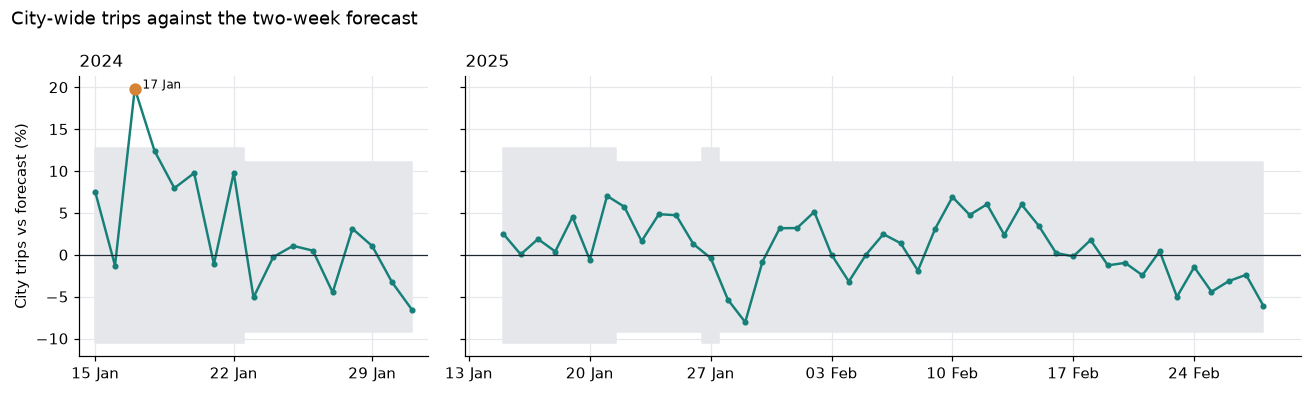

In [16]:
city = daily.groupby("request_date", as_index=False).trips.sum().assign(operator="City", touches_zone="All")
city_band, _ = band_alerts(city)
city_band = city_band.dropna(subset=["log_ratio"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True, gridspec_kw={"width_ratios": [1, 2.4]})
for ax, (year, g) in zip(axes, city_band.groupby(city_band.request_date.dt.year)):
    scale = np.where(g.references == 1, math.sqrt(4 / 3), 1.0)
    half = np.maximum(2.5 * g.robust_sd, math.log(1.03)) * scale
    ax.fill_between(g.request_date, 100 * np.expm1(g.center - half), 100 * np.expm1(g.center + half),
                    step="mid", color="#e5e7eb", label="alert band")
    ax.plot(g.request_date, 100 * np.expm1(g.log_ratio), color=TEAL, marker="o", ms=3, lw=1.6)
    hit = g[g.alert]
    ax.scatter(hit.request_date, 100 * np.expm1(hit.log_ratio), color=ORANGE, s=50, zorder=3)
    for _, r in hit.iterrows():
        ax.annotate(r.request_date.strftime("%d %b"), (r.request_date, 100 * np.expm1(r.log_ratio)),
                    xytext=(5, 0), textcoords="offset points", fontsize=8)
    ax.axhline(0, color=INK, lw=0.8)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.set_title(str(year))
axes[0].set_ylabel("City trips vs forecast (%)")
fig.suptitle("City-wide trips against the two-week forecast", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Reading.** Five of the seven open alerts had heavy rain or snow on a reference day, which pushed the forecast up or down; the fix is to skip bad-weather days when picking reference days. Two remain unexplained (Lyft outside the zone on 15 January, Uber in the zone on 28 February). The first two weeks of each January have no forecast because December data is not in scope; in production the history would be continuous.

## 3. Did the $1.50 fee reduce zone trips?

### 3.1 Matched year-on-year comparison

Two three-week windows that start on a Monday and each contain one MLK day: **8–28 Jan 2024** (no fee) and **6–26 Jan 2025** (fee). Trips not touching the zone are the comparison group. The counterfactual assumes zone trips would have grown at the same rate as outside trips:

$$\text{gap} = \frac{\text{zone}_{2025} / \text{zone}_{2024}}{\text{outside}_{2025} / \text{outside}_{2024}} - 1$$

In [17]:
fee_days = con.sql('''
    SELECT request_date, operator,
           pickup_zone IN (SELECT LocationID FROM zone_90) OR dropoff_zone IN (SELECT LocationID FROM zone_90) AS zone_90,
           touches_zone AS zone_95,
           pickup_zone IN (SELECT LocationID FROM zone_99) OR dropoff_zone IN (SELECT LocationID FROM zone_99) AS zone_99,
           COUNT(*) AS all_trips,
           SUM(CASE WHEN is_short THEN 1 ELSE 0 END) AS short_trips,
           SUM(CASE WHEN is_low_fare THEN 1 ELSE 0 END) AS low_fare_trips
    FROM labeled
    WHERE request_date BETWEEN DATE '2024-01-08' AND DATE '2024-01-28'
       OR request_date BETWEEN DATE '2025-01-06' AND DATE '2025-01-26'
    GROUP BY ALL
''').df()
fee_days["request_date"] = pd.to_datetime(fee_days.request_date).astype("datetime64[ns]")
fee_days["year"] = fee_days.request_date.dt.year
fee_days["week"] = (fee_days.request_date - pd.to_datetime(fee_days.year.map({2024: "2024-01-08", 2025: "2025-01-06"}))).dt.days // 7

week_rain = hourly.assign(year=hourly.request_date.dt.year, week=lambda h: (h.request_date - pd.to_datetime(
    h.year.map({2024: "2024-01-08", 2025: "2025-01-06"}))).dt.days // 7)
week_rain = week_rain[week_rain.week.between(0, 2) & (week_rain.request_date.dt.month == 1)].groupby("week").rain_mm.sum()
RAINIEST_WEEK = int(week_rain.idxmax())


def relative_gap(frame, zone_column, volume):
    cells = frame.groupby(["year", zone_column])[volume].sum()
    zone_growth = cells[(2025, True)] / cells[(2024, True)] - 1
    outside_growth = cells[(2025, False)] / cells[(2024, False)] - 1
    counterfactual = cells[(2024, True)] * (1 + outside_growth)
    return {"zone_growth": zone_growth, "outside_growth": outside_growth,
            "relative_gap": (1 + zone_growth) / (1 + outside_growth) - 1,
            "trips_vs_counterfactual": cells[(2025, True)] - counterfactual}


rows = []
for threshold in ("zone_90", "zone_95", "zone_99"):
    for scenario, data in [("all three weeks", fee_days), ("rainiest week dropped", fee_days[fee_days.week != RAINIEST_WEEK])]:
        for operator in ("All", "Uber", "Lyft"):
            subset = data if operator == "All" else data[data.operator == operator]
            for group in ("all_trips", "short_trips", "low_fare_trips"):
                rows.append({"zone_rule": threshold, "scenario": scenario, "operator": operator,
                             "trip_group": group, **relative_gap(subset, threshold, group)})
fee_sensitivity = save(pd.DataFrame(rows), "fee_sensitivity")
fee_effect = save(fee_sensitivity[(fee_sensitivity.zone_rule == "zone_95") & (fee_sensitivity.scenario == "all three weeks")]
                  .drop(columns=["zone_rule", "scenario"]), "fee_effect")
fee_effect.style.format({"zone_growth": "{:+.1%}", "outside_growth": "{:+.1%}", "relative_gap": "{:+.1%}",
                         "trips_vs_counterfactual": "{:+,.0f}"}).hide(axis="index")

operator,trip_group,zone_growth,outside_growth,relative_gap,trips_vs_counterfactual
All,all_trips,-4.4%,+5.6%,-9.5%,"-498,016"
All,short_trips,-5.3%,+7.1%,-11.6%,"-202,790"
All,low_fare_trips,-18.7%,+6.8%,-23.9%,"-160,192"
Uber,all_trips,-7.8%,+10.2%,-16.3%,"-675,416"
Uber,short_trips,-10.6%,+12.9%,-20.8%,"-300,139"
Uber,low_fare_trips,-33.4%,+14.2%,-41.7%,"-225,399"
Lyft,all_trips,+5.8%,-6.9%,+13.7%,"+154,411"
Lyft,short_trips,+13.4%,-7.1%,+22.0%,"+72,921"
Lyft,low_fare_trips,+26.5%,-12.0%,+43.7%,"+59,266"


In [18]:
robustness = (fee_sensitivity.groupby(["operator", "trip_group"], sort=False).relative_gap
              .agg(lowest="min", highest="max").reset_index())
robustness["same_sign_in_all_6_variants"] = np.sign(robustness.lowest) == np.sign(robustness.highest)
robustness.style.format({"lowest": "{:+.1%}", "highest": "{:+.1%}"}).hide(axis="index")

operator,trip_group,lowest,highest,same_sign_in_all_6_variants
All,all_trips,-9.5%,-9.3%,True
All,short_trips,-11.6%,-11.5%,True
All,low_fare_trips,-24.2%,-23.9%,True
Uber,all_trips,-16.3%,-16.0%,True
Uber,short_trips,-20.8%,-20.7%,True
Uber,low_fare_trips,-41.9%,-41.0%,True
Lyft,all_trips,+13.7%,+14.4%,True
Lyft,short_trips,+21.7%,+22.9%,True
Lyft,low_fare_trips,+42.0%,+43.7%,True


At face value: zone trips grew 9.5% slower than outside trips, short and low-fare trips more so, Uber fell and Lyft rose. The sign holds across zone thresholds of 90/95/99% and when the rainiest week is dropped. That stability only shows the number is not an artefact of those choices. It does not show the fee caused it.

### 3.2 Was the gap there before the fee?

The year-on-year comparison assumes zone and outside trips would have grown at the same pace without the fee. 2–4 January 2025 had no fee yet, so the gap on those days is a direct test. Each 2025 day is matched with the same weekday 364 days earlier; 1 January is skipped because New Year's Day falls on a different weekday each year.

In [19]:
def daily_gaps(daily):
    rows = []
    for day in pd.date_range("2025-01-02", "2025-01-29"):
        prior = day - pd.Timedelta(days=364)
        row = {"date": day, "prior_date": prior, "before_fee": day < FEE_START,
               "holiday_mismatch": (day in HOLIDAYS) != (prior in HOLIDAYS)}
        for operator in ("All", "Uber", "Lyft"):
            sel = daily if operator == "All" else daily[daily.operator == operator]
            cell = lambda d, z: sel[(sel.request_date == d) & (sel.touches_zone == z)].trips.sum()
            row |= {f"{operator}_zone_2024": cell(prior, True), f"{operator}_zone_2025": cell(day, True),
                    f"{operator}_outside_2024": cell(prior, False), f"{operator}_outside_2025": cell(day, False)}
            row[f"{operator}_gap"] = (row[f"{operator}_zone_2025"] / row[f"{operator}_zone_2024"]) / (
                row[f"{operator}_outside_2025"] / row[f"{operator}_outside_2024"]) - 1
        rows.append(row)
    return pd.DataFrame(rows)


def pooled_gap(frame, operator):
    s = frame[[f"{operator}_zone_2025", f"{operator}_zone_2024", f"{operator}_outside_2025", f"{operator}_outside_2024"]].sum()
    return (s.iloc[0] / s.iloc[1]) / (s.iloc[2] / s.iloc[3]) - 1


gaps = daily_gaps(daily)
main = gaps[gaps.date.between(*WINDOWS["jan_2025"])]
before = gaps[gaps.before_fee]
rng = np.random.default_rng(20250105)
summary = []
for operator in ("All", "Uber", "Lyft"):
    cols = [f"{operator}_zone_2025", f"{operator}_zone_2024", f"{operator}_outside_2025", f"{operator}_outside_2024"]
    values = main[cols].to_numpy(float)
    draws = []
    for _ in range(5000):
        s = values[rng.integers(0, len(values), len(values))].sum(axis=0)
        draws.append((s[0] / s[1]) / (s[2] / s[3]) - 1)
    summary.append({"operator": operator, "gap_2_4_jan_before_fee": pooled_gap(before, operator),
                    "gap_6_26_jan_with_fee": pooled_gap(main, operator),
                    "ci_low": np.percentile(draws, 2.5), "ci_high": np.percentile(draws, 97.5)})
pre_period = save(pd.DataFrame(summary), "fee_pre_period_check")
pre_period.style.format({c: "{:+.1%}" for c in pre_period.columns[1:]}).hide(axis="index")

operator,gap_2_4_jan_before_fee,gap_6_26_jan_with_fee,ci_low,ci_high
All,-13.8%,-9.5%,-10.9%,-8.0%
Uber,-21.6%,-16.3%,-17.6%,-15.0%
Lyft,+12.2%,+13.7%,+11.4%,+16.1%


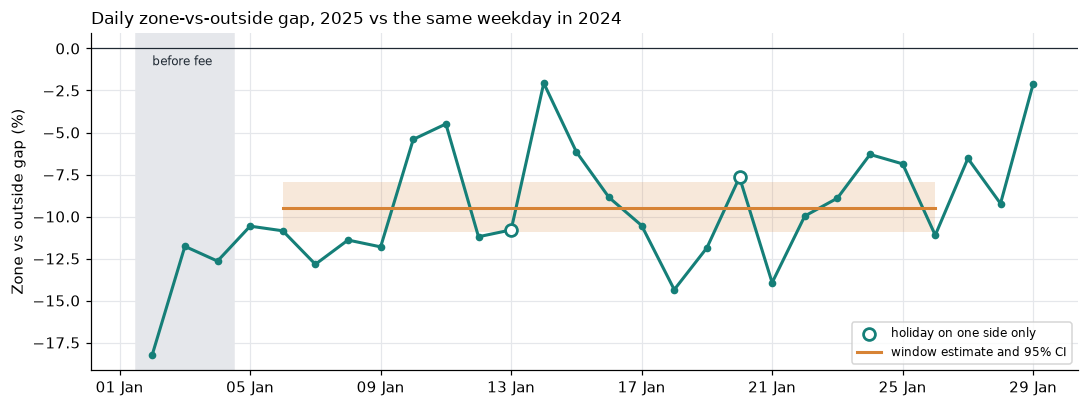

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axvspan(gaps.date.min() - pd.Timedelta(hours=12), FEE_START - pd.Timedelta(hours=12), color="#e5e7eb")
ax.plot(gaps.date, 100 * gaps.All_gap, color=TEAL, lw=2, marker="o", ms=4)
ax.scatter(gaps.loc[gaps.holiday_mismatch, "date"], 100 * gaps.loc[gaps.holiday_mismatch, "All_gap"],
           s=60, facecolor="white", edgecolor=TEAL, lw=1.8, zorder=3, label="holiday on one side only")
r = pre_period.iloc[0]
start, end = map(pd.Timestamp, WINDOWS["jan_2025"])
ax.fill_between([start, end], 100 * r.ci_low, 100 * r.ci_high, color=ORANGE, alpha=0.18, lw=0)
ax.plot([start, end], [100 * r.gap_6_26_jan_with_fee] * 2, color=ORANGE, lw=2, label="window estimate and 95% CI")
ax.axhline(0, color=INK, lw=0.8)
ax.text(gaps.date.min(), -1, "before fee", fontsize=8, color=INK)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylabel("Zone vs outside gap (%)")
ax.set_title("Daily zone-vs-outside gap, 2025 vs the same weekday in 2024")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

In [21]:
coverage = con.sql('''
    SELECT operator, touches_zone, COUNT(*) AS trips,
           SUM(CASE WHEN fee > 0 THEN 1 ELSE 0 END) AS trips_charged_fee
    FROM labeled
    WHERE request_date BETWEEN DATE '2025-01-06' AND DATE '2025-01-26'
    GROUP BY ALL ORDER BY ALL
''').df()
coverage["share_of_operator_fee_trips"] = coverage.trips_charged_fee / coverage.groupby("operator").trips_charged_fee.transform("sum")
coverage.style.format({"trips": "{:,.0f}", "trips_charged_fee": "{:,.0f}", "share_of_operator_fee_trips": "{:.1%}"}).hide(axis="index")

operator,touches_zone,trips,trips_charged_fee,share_of_operator_fee_trips
Lyft,False,"2,232,319","62,216",4.7%
Lyft,True,"1,282,171","1,252,967",95.3%
Uber,False,"7,116,769","195,162",5.4%
Uber,True,"3,466,694","3,451,308",94.6%


**Conclusion.** The gap was −13.8% before the fee started and −9.5% after it, and the daily series shows no step down on 5 January. The 2025 vs 2024 difference between zone and outside trips is a level shift that predates the fee, so this design cannot attribute it to the $1.50 charge. Three further caveats point the same way:

* The pre-fee check has only three days, and 2–3 January 2025 sit right after a midweek New Year holiday. The cleanest day, Saturday 4 January, still shows −12.7%.
* About 5% of fee-paying trips fall in the comparison group (through-zone trips and zones below the 95% threshold), so the control group is not fully untreated.
* Uber zone fares rose 9.2% over the same year (section 2.2), a price change unrelated to the fee.

The published estimate for the fee is a 0.5–1.5% drop in total ride-hailing (Zhang, Sang & Wu, 2026). To test it properly: add November–December 2023 and 2024, confirm the two groups moved in parallel before 5 January, then re-estimate.

## 4. Did Lyft's credit pay off?

Lyft issued a $1.50 credit on each fee-paying ride from 5 to 31 January, redeemable on a later ride. Uber offered nothing, so Lyft's **share of zone trips** should rise while the credit runs and fall back afterwards, relative to its share outside the zone.

### 4.1 Lyft share by week

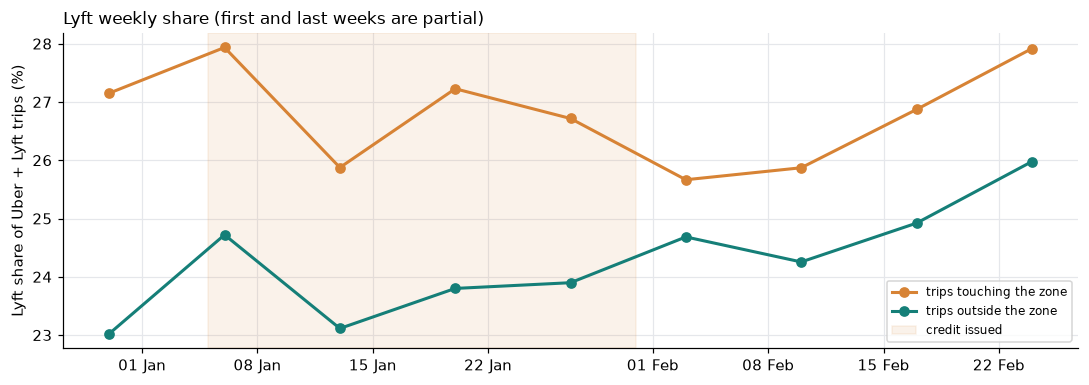

In [22]:
week = daily[daily.request_date.dt.year == 2025].assign(
    week_start=lambda d: d.request_date - pd.to_timedelta(d.request_date.dt.dayofweek, unit="D"))
weekly = week.pivot_table(index=["week_start", "touches_zone"], columns="operator", values="trips", aggfunc="sum").reset_index()
weekly["lyft_share"] = weekly.Lyft / (weekly.Lyft + weekly.Uber)
weekly["full_week"] = weekly.week_start.map(week.groupby("week_start").request_date.nunique()) == 7

fig, ax = plt.subplots(figsize=(10, 3.6))
for zone, color, label in [(True, ORANGE, "trips touching the zone"), (False, TEAL, "trips outside the zone")]:
    g = weekly[weekly.touches_zone == zone]
    ax.plot(g.week_start, 100 * g.lyft_share, color=color, marker="o", lw=2, label=label)
ax.axvspan(FEE_START, pd.Timestamp("2025-01-31"), color=ORANGE, alpha=0.1, label="credit issued")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylabel("Lyft share of Uber + Lyft trips (%)")
ax.set_title("Lyft weekly share (first and last weeks are partial)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [23]:
def share_table(daily, credit=WINDOWS["jan_2025"], after=WINDOWS["feb_2025"]):
    rows = []
    for period, (start, end) in [("credit (6-26 Jan)", credit), ("after (3-23 Feb)", after)]:
        part = daily[daily.request_date.between(start, end)]
        for zone, g in part.groupby("touches_zone"):
            t = g.groupby("operator").trips.sum()
            rows.append({"period": period, "touches_zone": zone, "lyft_trips": t.Lyft, "uber_trips": t.Uber,
                         "lyft_share": t.Lyft / (t.Lyft + t.Uber),
                         "lyft_fare_sum": g[g.operator == "Lyft"].fare_sum.sum(),
                         "lyft_economics_trips": g[g.operator == "Lyft"].economics_trips.sum()})
    table = pd.DataFrame(rows)
    s = table.set_index(["period", "touches_zone"]).lyft_share
    p_on, p_off = table.period.unique()
    did = (s[(p_on, True)] - s[(p_off, True)]) - (s[(p_on, False)] - s[(p_off, False)])
    return table, did, did / s[(p_off, True)]


credit_periods, share_gap, uplift = share_table(daily)
_, share_gap_late, uplift_late = share_table(daily, after=("2025-02-10", "2025-02-23"))
save(credit_periods, "credit_periods")
display(credit_periods.style.format({"lyft_trips": "{:,.0f}", "uber_trips": "{:,.0f}", "lyft_share": "{:.2%}",
                                     "lyft_fare_sum": "${:,.0f}", "lyft_economics_trips": "{:,.0f}"}).hide(axis="index"))
print(f"Difference-in-differences of Lyft zone share: {100 * share_gap:+.2f} pp -> uplift proxy {uplift:.2%}")
print(f"Dropping the first February week (credit carry-over): {100 * share_gap_late:+.2f} pp -> {uplift_late:.2%}")

period,touches_zone,lyft_trips,uber_trips,lyft_share,lyft_fare_sum,lyft_economics_trips
credit (6-26 Jan),False,"2,232,319","7,116,769",23.88%,"$45,843,459","2,224,420"
credit (6-26 Jan),True,"1,282,171","3,466,694",27.00%,"$33,060,642","1,276,117"
after (3-23 Feb),False,"2,365,453","7,244,232",24.62%,"$50,019,177","2,365,422"
after (3-23 Feb),True,"1,296,909","3,666,442",26.13%,"$34,904,863","1,296,892"


Difference-in-differences of Lyft zone share: +1.61 pp -> uplift proxy 6.15%
Dropping the first February week (credit carry-over): +1.34 pp -> 5.08%


### 4.2 Unit economics

For every 100 baseline trips, a blanket credit pays $1.50 on all 100 + *u* trips but only *u* are incremental. With contribution *m* per trip and credit cost *c* (both assumptions, since TLC has neither margin nor redemption):

$$\text{net} = u\,(m - c) - s\,c \qquad \text{break-even } u^* = \frac{s\,c}{m - c}$$

where *s* is the share of baseline trips that receive the credit (1 for blanket issuance).

In [24]:
def credit_economics(uplift, margin=6.0, credit=1.5, coverage=1.0, redemption=1.0, base=100):
    effective = credit * redemption
    extra = base * uplift
    cost = (base * coverage + extra) * effective
    return {"margin": margin, "redemption": redemption, "coverage": coverage, "uplift": uplift,
            "credit_cost": cost, "net_contribution": extra * margin - cost,
            "cost_per_extra_trip": cost / extra if extra else np.nan,
            "breakeven_uplift": coverage * effective / (margin - effective) if margin > effective else np.nan}


hand = credit_economics(0.03)
assert math.isclose(hand["credit_cost"], 154.5) and math.isclose(hand["cost_per_extra_trip"], 51.5)
scenarios = save(pd.DataFrame([credit_economics(uplift, m, coverage=s, redemption=r)
                               for m in (3, 6, 9) for r in (0.25, 0.5, 1.0) for s in (1.0, 0.3)]), "credit_scenarios")
observed = credit_economics(uplift)
print(f"Observed uplift proxy {uplift:.2%}, $6 contribution, full redemption: "
      f"${observed['cost_per_extra_trip']:.2f} of credit per incremental trip, break-even uplift {observed['breakeven_uplift']:.1%}")
breakeven = scenarios.pivot_table(index=["margin", "redemption"], columns="coverage", values="breakeven_uplift")
breakeven.columns = ["targeted (30% of trips)", "blanket (all trips)"]
breakeven.index = [f"${m:.0f} contribution, {r:.0%} redeemed" for m, r in breakeven.index]
breakeven.style.format("{:.1%}")

Observed uplift proxy 6.15%, $6 contribution, full redemption: $25.88 of credit per incremental trip, break-even uplift 33.3%


,targeted (30% of trips),blanket (all trips)
"$3 contribution, 25% redeemed",4.3%,14.3%
"$3 contribution, 50% redeemed",10.0%,33.3%
"$3 contribution, 100% redeemed",30.0%,100.0%
"$6 contribution, 25% redeemed",2.0%,6.7%
"$6 contribution, 50% redeemed",4.3%,14.3%
"$6 contribution, 100% redeemed",10.0%,33.3%
"$9 contribution, 25% redeemed",1.3%,4.3%
"$9 contribution, 50% redeemed",2.7%,9.1%
"$9 contribution, 100% redeemed",6.0%,20.0%


In [25]:
charged = int(coverage[coverage.operator == "Lyft"].trips_charged_fee.sum())
on = credit_periods[credit_periods.period.str.startswith("credit")].set_index("touches_zone")
lyft_zone_gmv = on.loc[True, "lyft_trips"] * on.loc[True, "lyft_fare_sum"] / on.loc[True, "lyft_economics_trips"]
lyft_gmv = on.lyft_trips.sum() * on.lyft_fare_sum.sum() / on.lyft_economics_trips.sum()
credit_cost = pd.DataFrame([{"redemption": r, "credit_cost_usd": 1.5 * charged * r,
                             "share_of_lyft_zone_gmv": 1.5 * charged * r / lyft_zone_gmv,
                             "share_of_all_lyft_gmv": 1.5 * charged * r / lyft_gmv} for r in (1.0, 0.5, 0.25)])
print(f"Lyft trips charged the fee, 6-26 Jan: {charged:,}")
credit_cost.style.format({"credit_cost_usd": "${:,.0f}", "share_of_lyft_zone_gmv": "{:.1%}", "share_of_all_lyft_gmv": "{:.1%}"}).hide(axis="index")

Lyft trips charged the fee, 6-26 Jan: 1,315,183


redemption,credit_cost_usd,share_of_lyft_zone_gmv,share_of_all_lyft_gmv
1.000000,"$1,972,774",5.9%,2.5%
0.500000,"$986,387",3.0%,1.2%
0.250000,"$493,194",1.5%,0.6%


**Reading.** The share data is consistent with a modest uplift (about 6%, or 5% when the first February week is excluded because credits issued on 31 January were still valid). At that level a blanket credit costs about $26 per incremental trip against an assumed $6 contribution. If every credit is redeemed, the programme costs up to 5.9% of Lyft's zone GMV. For scale only: Grab reported total incentives at 10.9% of On-Demand GMV in Q2 2026, across all products and incentive types. Two caveats: share moves mix new trips with trips taken from Uber, and the comparison relies on Lyft's outside-zone share being unaffected.

### 4.3 Designing the next test

A targeted credit aimed at short, low-fare zone riders, with 10% of eligible users randomly held out, answers the question this observational data cannot. Two design checks:

* **Sample size.** The minimum detectable effect (two-sided 5%, 80% power) is $\text{MDE} \approx 2.8\,\sigma\sqrt{1/n_T + 1/n_C}$. TLC has no rider IDs, so the per-rider coefficient of variation is assumed and must be replaced with real pre-period data. CUPED (adjusting for each rider's pre-period trips) shrinks the variance by $1 - R^2$.
* **Market-level interventions.** Driver incentives in rain hours cannot be split by rider, so they need a switchback design that alternates treatment by time slice. Using the real hourly variance, consecutive hours are strongly correlated, which inflates the variance by $(1+\rho)/(1-\rho)$.

In [26]:
Z = 1.959964 + 0.841621


def mde(sd, n_treat, n_control, design_effect=1.0):
    return Z * sd * math.sqrt(design_effect * (1 / n_treat + 1 / n_control))


holdout = pd.DataFrame([{"eligible_riders": n, "cv_per_rider": cv, "cuped_r2": r2,
                         "mde": mde(cv * math.sqrt(1 - r2), 0.9 * n, 0.1 * n)}
                        for n in (50_000, 200_000, 500_000) for cv in (1.5, 2.5) for r2 in (0.0, 0.3)])
holdout_view = holdout.pivot_table(index="eligible_riders", columns=["cv_per_rider", "cuped_r2"], values="mde")
holdout_view.columns = [f"CV {cv}, {'CUPED R²=' + str(r2) if r2 else 'no CUPED'}" for cv, r2 in holdout_view.columns]
holdout_view.index = [f"{n:,} riders" for n in holdout_view.index]
display(holdout_view.style.format("{:.1%}"))

hours_2025 = hourly[(hourly.request_date >= "2025-01-06") & ~hourly.is_holiday].copy()
hours_2025["month"] = hours_2025.request_date.dt.month
rain_share = ((hours_2025.rain_mm >= 0.5) & (hours_2025.snowfall_cm == 0)).mean()
rows = []
for metric in ("trips", "median_wait"):
    log_value = np.log(hours_2025[metric])
    resid = log_value - log_value.groupby([hours_2025.month, hours_2025.day_of_week, hours_2025.hour]).transform("median")
    for block in (1, 2):
        series = resid.groupby((hours_2025.request_hour - hours_2025.request_hour.min()).dt.total_seconds() // (3600 * block)).mean()
        sd, rho = series.std(), series.autocorr()
        effect = (1 + rho) / (1 - rho)
        for days, scope in [(14, "all hours"), (14, "rain hours only"), (56, "rain hours only")]:
            slices = days * 24 // block if scope == "all hours" else max(round(days * 24 * rain_share / block), 2)
            rows.append({"metric": metric, "slice_hours": block, "days": days, "scope": scope, "slices": slices,
                         "lag1_autocorr": rho, "mde": mde(sd, slices / 2, slices / 2, effect)})
switchback = save(pd.DataFrame(rows), "switchback_power")
display(switchback.style.format({"lag1_autocorr": "{:.2f}", "mde": "{:.1%}"}).hide(axis="index"))


def srm_p_value(treatment, control, expected_share=0.9):
    total = treatment + control
    chi2 = (treatment - total * expected_share) ** 2 / (total * expected_share) + \
           (control - total * (1 - expected_share)) ** 2 / (total * (1 - expected_share))
    return math.erfc(math.sqrt(chi2 / 2))


print(f"Sample ratio check, 180,000 / 20,000 riders: p = {srm_p_value(180_000, 20_000):.2f} (fine)")
print(f"Sample ratio check, 179,200 / 20,800 riders: p = {srm_p_value(179_200, 20_800):.1e} (stop and fix assignment)")

,"CV 1.5, no CUPED","CV 1.5, CUPED R²=0.3","CV 2.5, no CUPED","CV 2.5, CUPED R²=0.3"
"50,000 riders",6.3%,5.2%,10.4%,8.7%
"200,000 riders",3.1%,2.6%,5.2%,4.4%
"500,000 riders",2.0%,1.7%,3.3%,2.8%


metric,slice_hours,days,scope,slices,lag1_autocorr,mde
trips,1,14,all hours,336,0.78,4.0%
trips,1,14,rain hours only,11,0.78,22.2%
trips,1,56,rain hours only,45,0.78,11.0%
trips,2,14,all hours,168,0.68,4.3%
trips,2,14,rain hours only,6,0.68,22.8%
trips,2,56,rain hours only,23,0.68,11.6%
median_wait,1,14,all hours,336,0.79,6.8%
median_wait,1,14,rain hours only,11,0.79,37.8%
median_wait,1,56,rain hours only,45,0.79,18.7%
median_wait,2,14,all hours,168,0.66,7.0%


Sample ratio check, 180,000 / 20,000 riders: p = 1.00 (fine)
Sample ratio check, 179,200 / 20,800 riders: p = 2.5e-09 (stop and fix assignment)


**Reading.** A rider-level holdout is cheap to power: 50,000 eligible riders already detect a 6% effect, well below the 10% break-even for targeted credit. Rain-hour switchbacks are the hard case. Only 3.4% of winter hours have rain, so 14 days give about 11 rain slices and can only detect effects above 20%. Run them over a full season, across several cities, or on all hours with a weather interaction.

**Proposed test.** Hypothesis: a $1.50 credit for riders whose last 28 days were mostly short, low-fare zone trips keeps their trips at a lower subsidy than blanket issuance. Primary metric: zone trips per assigned rider over at least 14 days, counting riders with zero trips. Guardrails: contribution per trip, wait time, cancellation rate. Expand only if incremental net contribution per assigned rider is positive with guardrails intact; check the sample ratio before reading any result.

## 5. Holiday-week forecast: 17–23 February 2025

### 5.1 Information available at the cutoff

The plan is made at the end of 16 February, so history only includes trips that were **completed** by then: a trip requested late on 16 February but finished on the 17th is excluded. The zone list was calibrated on 5–31 January, also before the cutoff. No weather forecast, credit result or test-week actual enters the forecast.

In [27]:
history = con.sql('''
    SELECT request_date, operator, touches_zone, COUNT(*) AS trips
    FROM labeled
    WHERE request_date BETWEEN DATE '2025-01-01' AND DATE '2025-02-16'
      AND dropoff_datetime < TIMESTAMP '2025-02-17'
    GROUP BY ALL
''').df()
history["request_date"] = pd.to_datetime(history.request_date).astype("datetime64[ns]")
known = history.set_index(["request_date", "operator", "touches_zone"]).trips
final = daily[daily.request_date <= CUTOFF].set_index(["request_date", "operator", "touches_zone"]).trips
assert known.index.get_level_values(0).max() == CUTOFF
print(f"Trips completed after the cutoff and excluded from history: {int((final - known.reindex(final.index)).sum()):,}")

Trips completed after the cutoff and excluded from history: 9,961


### 5.2 Three baselines

| Method | Forecast for day *D* in each segment |
|---|---|
| **B1** | trips on *D* − 7 |
| **B2** | mean of *D* − 7 and *D* − 14 |
| **B3** | B2, with 17 Feb multiplied by the segment's MLK factor: trips on 20 Jan ÷ mean of 13 and 27 Jan |

B2 is chosen as the planning baseline **before** seeing the test week, because averaging two weeks protects against one unusual day. B3 is kept as a holiday scenario: one MLK day is thin evidence for how Presidents' Day behaves.

In [28]:
def holiday_week_forecast(known):
    rows, factors = [], []
    for operator, zone in SEGMENTS:
        at = lambda day: known[(pd.Timestamp(day), operator, zone)]
        factor = at("2025-01-20") / ((at("2025-01-13") + at("2025-01-27")) / 2)
        factors.append({"segment": segment_name(operator, zone), "mlk_factor": factor})
        for day in pd.date_range("2025-02-17", "2025-02-23"):
            b1 = at(day - pd.Timedelta(days=7))
            b2 = (b1 + at(day - pd.Timedelta(days=14))) / 2
            rows.append({"request_date": day, "operator": operator, "touches_zone": zone, "B1": b1, "B2": b2,
                         "B3": b2 * (factor if day == pd.Timestamp("2025-02-17") else 1.0)})
    return pd.DataFrame(rows), pd.DataFrame(factors)


forecast, mlk = holiday_week_forecast(known)
save(forecast, "forecast_week")
display(mlk.style.format({"mlk_factor": "{:.3f}"}).hide(axis="index"))
plan = forecast.groupby("request_date")[["B1", "B2", "B3"]].sum()
plan.index = plan.index.strftime("%a %d %b")
plan.loc["Total"] = plan.sum()
plan.style.format("{:,.0f}")

segment,mlk_factor
Uber zone,0.946
Uber outside,1.019
Lyft zone,0.997
Lyft outside,0.995


,B1,B2,B3
request_date,,,
Mon 17 Feb,"611,032","591,617","589,149"
Tue 18 Feb,"636,008","623,512","623,512"
Wed 19 Feb,"673,249","662,746","662,746"
Thu 20 Feb,"715,445","712,804","712,804"
Fri 21 Feb,"814,988","793,364","793,364"
Sat 22 Feb,"817,635","799,268","799,268"
Sun 23 Feb,"683,248","688,156","688,156"
Total,"4,951,605","4,871,468","4,869,000"


### 5.3 Backtest against the actual week

WAPE = Σ|forecast − actual| ÷ Σ actual, computed over all 28 cells (it is not an average of segment WAPEs). Bias = Σ(forecast − actual) ÷ Σ actual.

In [29]:
actual = daily[daily.request_date.between("2025-02-17", "2025-02-23")][["request_date", "operator", "touches_zone", "trips"]]
scored = forecast.merge(actual, on=["request_date", "operator", "touches_zone"], validate="one_to_one")
assert len(scored) == 28


def accuracy(frame):
    return pd.DataFrame({m: {"MAE": (frame[m] - frame.trips).abs().mean(),
                             "WAPE": (frame[m] - frame.trips).abs().sum() / frame.trips.sum(),
                             "bias": (frame[m] - frame.trips).sum() / frame.trips.sum()} for m in ("B1", "B2", "B3")}).T


holiday_day = scored.request_date == pd.Timestamp("2025-02-17")
scores = pd.concat({"whole week": accuracy(scored), "17 Feb (holiday)": accuracy(scored[holiday_day]),
                    "18-23 Feb": accuracy(scored[~holiday_day])}, names=["scope", "method"]).reset_index()
save(scores, "forecast_scores")
display(scores.style.format({"MAE": "{:,.0f}", "WAPE": "{:.2%}", "bias": "{:+.2%}"}).hide(axis="index"))
by_segment = scored.assign(segment=[segment_name(o, z) for o, z in zip(scored.operator, scored.touches_zone)])
by_segment.groupby("segment").apply(lambda g: accuracy(g).WAPE, include_groups=False).style.format("{:.2%}")

scope,method,MAE,WAPE,bias
whole week,B1,"7,660",4.45%,+2.73%
whole week,B2,"5,998",3.48%,+1.06%
whole week,B3,"6,220",3.61%,+1.01%
17 Feb (holiday),B1,"5,312",3.60%,+3.48%
17 Feb (holiday),B2,"2,084",1.41%,+0.19%
17 Feb (holiday),B3,"3,634",2.46%,-0.23%
18-23 Feb,B1,"8,052",4.57%,+2.62%
18-23 Feb,B2,"6,650",3.77%,+1.19%
18-23 Feb,B3,"6,650",3.77%,+1.19%


WAPE,B1,B2,B3
segment,,,
Lyft outside,4.02%,3.64%,3.69%
Lyft zone,6.00%,5.81%,5.84%
Uber outside,4.10%,2.54%,2.78%
Uber zone,4.87%,4.43%,4.40%


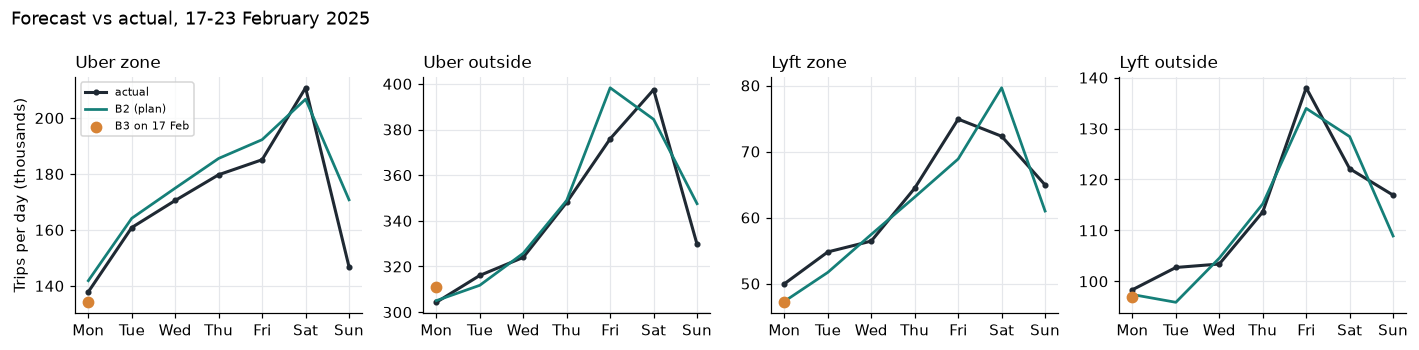

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharex=True)
for ax, (operator, zone) in zip(axes, SEGMENTS):
    g = scored[(scored.operator == operator) & (scored.touches_zone == zone)]
    ax.plot(g.request_date, g.trips / 1e3, color=INK, lw=2, marker="o", ms=3, label="actual")
    ax.plot(g.request_date, g.B2 / 1e3, color=TEAL, lw=1.8, label="B2 (plan)")
    ax.scatter(g.request_date.iloc[:1], g.B3.iloc[:1] / 1e3, color=ORANGE, s=45, zorder=3, label="B3 on 17 Feb")
    ax.set_title(segment_name(operator, zone))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))
axes[0].set_ylabel("Trips per day (thousands)")
axes[0].legend(fontsize=7)
fig.suptitle("Forecast vs actual, 17-23 February 2025", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Reading.** B2 was the most accurate method over the week (WAPE 3.5%) and on the holiday itself (1.4%). The MLK factor made 17 February worse in three of four segments and helped only Uber zone trips, slightly: Presidents' Day did not behave like MLK. The largest single miss is Uber zone trips on Sunday 23 February (B2 about 171k, actual 147k); the same day is flagged in section 2.4 because its reference day, 16 February, had 17 hours of rain. With one holiday of each kind this is not proof that B2 always wins, but it supports keeping holiday factors as a scenario until several years of holidays are available.

## 6. Recommendations

| Area | Recommendation | Evidence | Next step |
|---|---|---|---|
| Holiday-week plan | Plan **4.87 M** completed trips for 17–23 Feb with B2; show B3 as a downside scenario for the holiday | B2 WAPE 3.5% in backtest, lowest of three | Track daily against plan; refresh B2 each morning |
| Monitoring | Replace the ±7% rule with a 2.5-SD band around the two-week forecast; skip bad-weather reference days | 118 → 9 alerts; 5 of 7 open alerts trace to weather on a reference day | Re-calibrate the band monthly |
| Pricing (fee) | Do not quote the −9.5% gap as a fee effect | Gap of −13.8% before the fee; no break on 5 Jan | Add Nov–Dec 2023/2024 and test for parallel pre-trends |
| Campaigns (credit) | Replace blanket credit with a targeted test and a 10% randomized holdout | Blanket credit ≈ $26 per incremental trip at $6 contribution; break-even 33% uplift | Pre-register metric, guardrails and sample-ratio check |
| Weather | Use rain as an operations trigger, not a demand multiplier | Heavy rain +7.7% trips, +0.9% wait; winter samples too small | Collect a full year of weather-matched hours |

**Limits.** TLC records completed trips only, so cancelled or unfulfilled requests, driver supply, rider IDs, credit redemption and true margins are not observed. All effects are observational. The zone label is inferred from fees paid and does not capture through-zone trips. The forecast simulation assumes trip records were available at the cutoff, whereas TLC publishes monthly.

In [31]:
yoy = growth[growth.operator == "All"].iloc[0]
fee = pre_period.iloc[0]
heavy_rain = rain_factors[(rain_factors.study == "summer 2024") & (rain_factors.weather == "rain > 2 mm/h")].iloc[0]
week_wape = scores[scores.scope == "whole week"].WAPE
scorecard = pd.DataFrame([
    ("Completed trips analysed", f"{retained:,}"),
    ("Trip growth, matched January windows", f"{yoy.trips_growth:+.1%}"),
    ("Zone vs outside gap, 6-26 Jan (95% CI)", f"{fee.gap_6_26_jan_with_fee:+.1%} ({fee.ci_low:+.1%} to {fee.ci_high:+.1%})"),
    ("Same gap before the fee, 2-4 Jan", f"{fee.gap_2_4_jan_before_fee:+.1%}"),
    ("Lyft zone share, difference-in-differences", f"{100 * share_gap:+.2f} pp (uplift proxy {uplift:.1%})"),
    ("Credit cost per incremental trip ($6 contribution)", f"${observed['cost_per_extra_trip']:.2f}"),
    ("Heavy rain: trips / wait factor (summer)", f"{heavy_rain.trips_factor:.3f} / {heavy_rain.wait_factor:.3f}"),
    ("Alerts: fixed 7% rule vs forecast band", f"{fixed.alert.sum()} vs {band.alert.sum()}"),
    ("Holiday-week plan (B2)", f"{forecast.B2.sum():,.0f} trips"),
    ("Backtest WAPE B1 / B2 / B3", " / ".join(f"{w:.2%}" for w in week_wape)),
], columns=["metric", "value"])
scorecard.style.hide(axis="index")

metric,value
Completed trips analysed,"59,407,013"
"Trip growth, matched January windows",+2.0%
"Zone vs outside gap, 6-26 Jan (95% CI)",-9.5% (-10.9% to -8.0%)
"Same gap before the fee, 2-4 Jan",-13.8%
"Lyft zone share, difference-in-differences",+1.61 pp (uplift proxy 6.2%)
Credit cost per incremental trip ($6 contribution),$25.88
Heavy rain: trips / wait factor (summer),1.077 / 1.009
Alerts: fixed 7% rule vs forecast band,118 vs 9
Holiday-week plan (B2),"4,871,468 trips"
Backtest WAPE B1 / B2 / B3,4.45% / 3.48% / 3.61%
